<a href="https://colab.research.google.com/github/rrdaks23/Forestry_RS/blob/main/Biomass_Modelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install library yang dibutuhkan untuk GEE, pengolahan data, grafik, dan statistik
!pip install geemap pandas numpy matplotlib seaborn scipy

import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Autentikasi dan Inisialisasi Google Earth Engine
ee.Authenticate()
ee.Initialize(project='collaboration-512712') # Ganti dengan Project ID GEE Anda

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 16.5 MB/s  0:00:00


In [2]:
# 1. Masukkan path asset GEE wilayah Anda (contoh format: 'users/username_anda/nama_asset_anda')
asset_path = 'projects/collaboration-512712/assets/Kota_kab_Sumbar'
region = ee.FeatureCollection(asset_path)

# 2. Fungsi komposit citra tahunan diskrit
start_2021 = '2021-03-01'
end_2021 = '2021-10-31'

start_2025 = '2025-03-01'
end_2025 = '2025-10-31'

# 2. Fungsi komposit citra dinamis berdasarkan rentang tanggal
def get_snapshot(start_date, end_date, geometry):
    # Komposit Sentinel-2 (Bebas Awan < 20%)
    s2 = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED') \
           .filterBounds(geometry) \
           .filterDate(start_date, end_date) \
           .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20)) \
           .median()

    # Hitung Indeks Vegetasi
    ndvi = s2.normalizedDifference(['B8', 'B4']).rename('NDVI')
    evi = s2.expression(
        '2.5 * ((NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 10000))',
        {
            'NIR': s2.select('B8'),
            'RED': s2.select('B4'),
            'BLUE': s2.select('B2')
        }
    ).rename('EVI')

    # Komposit Sentinel-1 SAR (Polarisasi VV & VH - Tembus Awan)
    s1 = ee.ImageCollection('COPERNICUS/S1_GRD') \
           .filterBounds(geometry) \
           .filterDate(start_date, end_date) \
           .filter(ee.Filter.eq('instrumentMode', 'IW')) \
           .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')) \
           .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH')) \
           .select(['VV', 'VH']) \
           .median()

    # Gabungkan seluruh fitur menjadi satu stack raster
    stack = s2.select(['B2', 'B3', 'B4', 'B8', 'B11', 'B12']) \
              .addBands([ndvi, evi, s1]) \
              .clip(geometry)

    return stack

In [3]:
print("Menyiapkan data latih dan melatih model Machine Learning (Baseline 2020)...")

target_2020 = ee.Image('ESA/CCI/Above_Ground_Biomass/V6_0/2020').select('agb').clip(region)
features_2020 = get_snapshot('2020-01-01', '2020-12-31', region)

training_image = target_2020.rename('biomass').addBands(features_2020)

training_samples = training_image.sample(
    region=region.geometry(),
    scale=100,
    numPixels=5000,
    geometries=True
)

band_names = ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'EVI', 'VV', 'VH']

Menyiapkan data latih dan melatih model Machine Learning (Baseline 2020)...


In [4]:
# Latih Model Random Forest Regressor dengan 500 pohon
rf_model = ee.Classifier.smileRandomForest(numberOfTrees=500) \
             .setOutputMode('REGRESSION') \
             .train(
                 features=training_samples,
                 classProperty='biomass',
                 inputProperties=band_names
             )
print("Model Random Forest (500 Trees) berhasil dilatih!")

Model Random Forest (500 Trees) berhasil dilatih!


In [5]:
print("Memproses prediksi snapshot biomassa tahun 2021 dan 2025...")

# Menggunakan rentang waktu sesuai permintaan
features_2021 = get_snapshot(start_2021, end_2021, region)
features_2025 = get_snapshot(start_2025, end_2025, region)

biomass_2021 = features_2021.classify(rf_model, 'biomass_2021')
biomass_2025 = features_2025.classify(rf_model, 'biomass_2025')
biomass_change = biomass_2025.subtract(biomass_2021).rename('biomass_change')

loss_image = biomass_change.updateMask(biomass_change.lt(0)).abs().rename('loss')
gain_image = biomass_change.updateMask(biomass_change.gt(0)).rename('gain')

Memproses prediksi snapshot biomassa tahun 2021 dan 2025...


In [6]:
# 1. Tumpuk (stack) raster analisis
analysis_stack = biomass_2021.rename('Biomass_2021') \
                 .addBands(biomass_2025.rename('Biomass_2025')) \
                 .addBands(loss_image.rename('Loss_Tons')) \
                 .addBands(gain_image.rename('Gain_Tons'))

# 2. Reduksi statistik per poligon (Kabupaten/Kota berdasarkan kolom 'WADMKK')
stats_per_region = analysis_stack.reduceRegions(
    collection=region,
    reducer=ee.Reducer.mean().combine(reducer2=ee.Reducer.sum(), sharedInputs=True),
    scale=10
)

# 3. Fungsi untuk merapikan struktur kolom agar bersih dan terformat sesuai permintaan
def clean_and_format_table(feature):
    wamdkk = feature.get('WADMKK')
    b21_total = feature.get('Biomass_2021_sum')
    b25_total = feature.get('Biomass_2025_sum')
    loss_total = feature.get('Loss_Tons_sum')
    gain_total = feature.get('Gain_Tons_sum')
    net_change = ee.Number(gain_total).subtract(ee.Number(loss_total))

    return ee.Feature(None, {
        'WADMKK': wamdkk,
        'Total_Biomassa_2021_Ton': b21_total,
        'Total_Biomassa_2025_Ton': b25_total,
        'Kehilangan_Loss_Ton': loss_total,
        'Penambahan_Gain_Ton': gain_total,
        'Perubahan_Netto_Ton': net_change
    })

clean_table = stats_per_region.map(clean_and_format_table)

# 4. Kirim task ekspor langsung ke Google Drive (Aman dari timeout Colab)
print("Mengirim task ekspor tabel bersih ke Google Drive...")
task = ee.batch.Export.table.toDrive(
    collection=clean_table,
    description='Rekapitulasi_Biomassa_2021_2025_Fixed',
    folder='GEE_For porto',
    fileFormat='CSV'
)
task.start()

print("\n" + "="*60)
print("Task ekspor file CSV bersih per kabupaten/kota sedang berjalan di background Google Drive.")
print("Silakan cek folder 'GEE_Research' di Google Drive Anda beberapa saat lagi.")
print("Format kolom file CSV sudah otomatis tersusun: wamdkk, total biomassa, loss, gain, dan netto.")
print("="*60)

Mengirim task ekspor tabel bersih ke Google Drive...

Task ekspor file CSV bersih per kabupaten/kota sedang berjalan di background Google Drive.
Silakan cek folder 'GEE_Research' di Google Drive Anda beberapa saat lagi.
Format kolom file CSV sudah otomatis tersusun: wamdkk, total biomassa, loss, gain, dan netto.


In [8]:
print("Melakukan pengambilan sampel piksel untuk Uji Statistik Komparatif...")

eval_image = biomass_2021.addBands(biomass_2025)
# Membatasi numPixels menjadi 500 untuk menghindari limit memori interaktif GEE
eval_samples = eval_image.sample(region=region.geometry(), scale=1000, numPixels=500, seed=42)
df_stats = geemap.ee_to_df(eval_samples).dropna()

b21 = df_stats['biomass_2021']
b25 = df_stats['biomass_2025']

# Melakukan Paired T-Test dan Wilcoxon Signed-Rank Test
t_stat, p_val_t = stats.ttest_rel(b21, b25)
wilcox_stat, p_val_w = stats.wilcoxon(b21, b25)

print("\n" + "="*50)
print("=== HASIL UJI STATISTIK CADANGAN BIOMASSA (2021 vs 2026) ===")
print("="*50)
print(f"1. Paired T-Test Statistic : {t_stat:.4f} | p-value: {p_val_t:.4e}")
print(f"2. Wilcoxon Signed-Rank Stat : {wilcox_stat:.4f} | p-value: {p_val_w:.4e}")
print("-"*50)
if p_val_t < 0.05:
    print("Kesimpulan: Terdapat perbedaan yang SIGNIFIKAN secara statistik pada cadangan biomassa antara tahun 2021 dan 2025 (p < 0.05).")
else:
    print("Kesimpulan: Tidak terdapat perbedaan yang signifikan secara statistik antara tahun 2021 dan 2025.")
print("="*50)

Melakukan pengambilan sampel piksel untuk Uji Statistik Komparatif...

=== HASIL UJI STATISTIK CADANGAN BIOMASSA (2021 vs 2026) ===
1. Paired T-Test Statistic : 3.5100 | p-value: 4.9747e-04
2. Wilcoxon Signed-Rank Stat : 32625.0000 | p-value: 3.0532e-05
--------------------------------------------------
Kesimpulan: Terdapat perbedaan yang SIGNIFIKAN secara statistik pada cadangan biomassa antara tahun 2021 dan 2025 (p < 0.05).


/tmp/ipykernel_5478/2631496496.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=mean_data, x='Tahun', y='Rata-rata Biomassa (Mg/ha)', palette='crest')


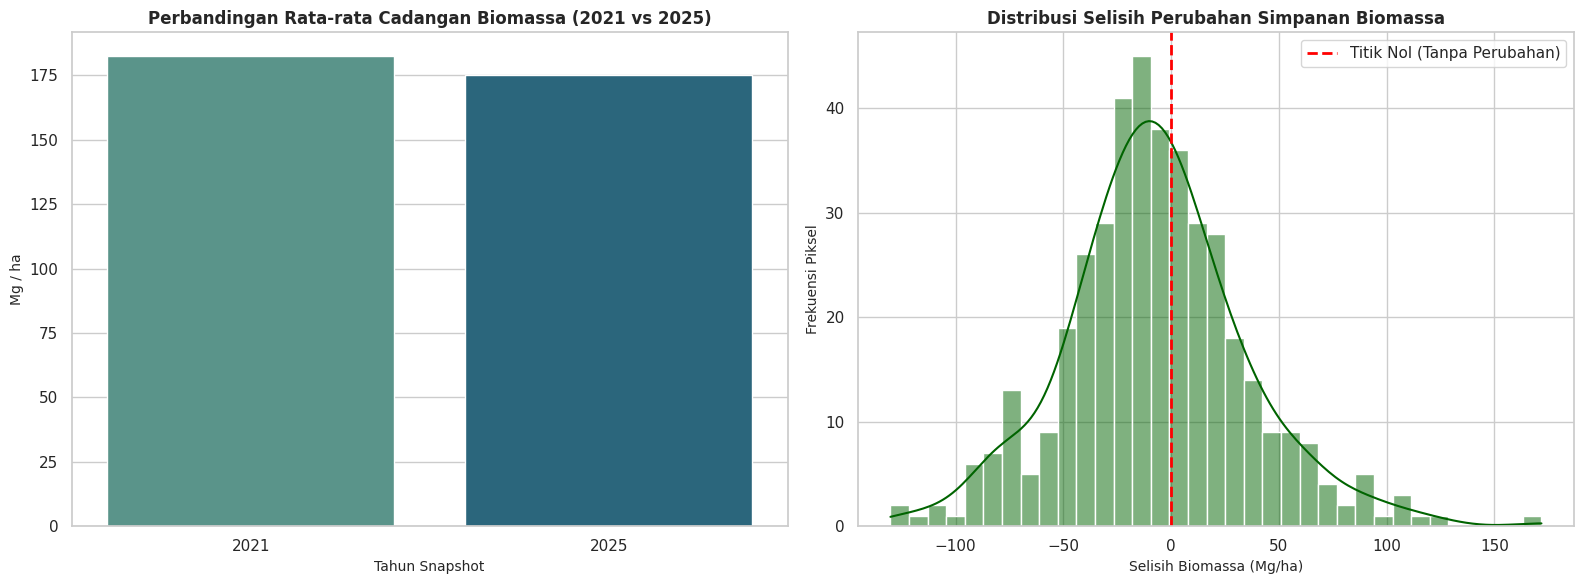

In [10]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 6))

# Grafik 1: Perbandingan Rata-rata Biomassa (2021 vs 2026)
plt.subplot(1, 2, 1)
mean_data = pd.DataFrame({
    'Tahun': ['2021', '2025'],
    'Rata-rata Biomassa (Mg/ha)': [b21.mean(), b25.mean()]
})
sns.barplot(data=mean_data, x='Tahun', y='Rata-rata Biomassa (Mg/ha)', palette='crest')
plt.title('Perbandingan Rata-rata Cadangan Biomassa (2021 vs 2025)', fontsize=12, fontweight='bold')
plt.ylabel('Mg / ha', fontsize=10)
plt.xlabel('Tahun Snapshot', fontsize=10)

# Grafik 2: Distribusi Selisih Perubahan Biomassa
plt.subplot(1, 2, 2)
change_vals = b25 - b21
sns.histplot(change_vals, kde=True, color='darkgreen', bins=35)
plt.axvline(0, color='red', linestyle='--', linewidth=2, label='Titik Nol (Tanpa Perubahan)')
plt.title('Distribusi Selisih Perubahan Simpanan Biomassa', fontsize=12, fontweight='bold')
plt.xlabel('Selisih Biomassa (Mg/ha)', fontsize=10)
plt.ylabel('Frekuensi Piksel', fontsize=10)
plt.legend()

plt.tight_layout()
plt.show()

In [11]:
# Inisialisasi peta interaktif geemap
Map = geemap.Map()

# Mengatur Basemap menjadi Google Satellite menggunakan add_basemap yang didukung geemap
Map.add_basemap('SATELLITE')

# Auto-center peta ke batas wilayah asset Anda
Map.centerObject(region, 9)

vis_biomass = {
    'min': 0,
    'max': 350,
    'palette': ['#ffffcc', '#a1dab4', '#41b6c4', '#2c7fb8', '#253494', '#081d58']
}

vis_change = {
    'min': -50,
    'max': 50,
    'palette': ['#d7191c', '#fdae61', '#ffffbf', '#abdda4', '#2b83ba']
}

# Tambahkan layer ke peta
Map.addLayer(region, {'strokeColor': 'ff0000', 'fillColor': '00000000'}, 'Batas Wilayah Asset')
Map.addLayer(biomass_2021, vis_biomass, 'Snapshot Biomassa 2021')
Map.addLayer(biomass_2025, vis_biomass, 'Snapshot Biomassa 2025')
Map.addLayer(biomass_change, vis_change, 'Perbandingan Diskrit (2021 vs 2025)')

Map.add_layer_control()
display(Map)

# ==========================================
# MENAMBAHKAN LEGENDA PETA
# ==========================================

# 1. Kamus Legenda Cadangan Biomassa (Mg/ha)
legend_biomass = {
    'Sangat Tinggi (> 300 Mg/ha)': '#081d58',
    'Tinggi (250 - 300 Mg/ha)': '#253494',
    'Sedang (150 - 250 Mg/ha)': '#2c7fb8',
    'Agak Rendah (100 - 150 Mg/ha)': '#41b6c4',
    'Rendah (50 - 100 Mg/ha)': '#a1dab4',
    'Sangat Rendah (< 50 Mg/ha)': '#ffffcc'
}

# 2. Kamus Legenda Perubahan Biomassa (Loss / Gain)
legend_change = {
    'Kehilangan Signifikan (Loss)': '#d7191c',
    'Kehilangan Ringan': '#fdae61',
    'Stabil / Tanpa Perubahan': '#ffffbf',
    'Penambahan Ringan': '#abdda4',
    'Penambahan Signifikan (Gain)': '#2b83ba'
}

# Masukkan legenda ke dalam peta geemap
Map.add_legend(title="Cadangan Biomassa (Mg/ha)", legend_dict=legend_biomass)
Map.add_legend(title="Perubahan Biomassa (2018-2026)", legend_dict=legend_change)

Map.add_layer_control()
display(Map)

Map(center=[-0.8499338557811682, 100.46695679495438], controls=(WidgetControl(options=['position', 'transparen…

Map(center=[-0.8499338557811682, 100.46695679495438], controls=(WidgetControl(options=['position', 'transparen…

In [14]:
import os
import pandas as pd
from google.colab import drive

# 1. Pastikan Google Drive sudah di-mount
drive.mount('/content/drive')

# Tentukan folder tujuan di Google Drive
drive_folder = '/content/drive/MyDrive/GEE_Research'
os.makedirs(drive_folder, exist_ok=True)

print("="*65)
print("=== 1. PROSES EKSPOR TABEL KABUPATEN/KOTA (CSV) KE GEE DRIVE ===")
print("="*65)
print("Mengirim task ekspor tabel ke Google Drive untuk menghindari interactive timeout...")

# Menggunakan Export Task background untuk memproses tabel (Aman dari timeout)
task_table = ee.batch.Export.table.toDrive(
    collection=clean_table,
    description='Rekapitulasi_Biomassa_2021_2025_Direct',
    folder='GEE_Research',
    fileFormat='CSV'
)
task_table.start()
print("-> Task ekspor tabel berhasil dikirim ke background GEE!")
print("Silakan cek tab 'Tasks' di GEE console atau tunggu beberapa saat hingga file muncul di Google Drive.")

print("\n" + "="*65)
print("=== 2. PROSES EKSPOR DATA RASTER SPASIAL (TIFF) TERPISAH KE GEE DRIVE ===")
print("="*65)

# Daftar layer raster yang akan diekspor secara terpisah
raster_dict = {
    'Raster_Biomassa_2021': biomass_2021,
    'Raster_Biomassa_2025': biomass_2025,
    'Raster_Perubahan_Netto_2021_2025': biomass_change,
    'Raster_Kehilangan_Loss': loss_image,
    'Raster_Penambahan_Gain': gain_image
}

# Looping untuk mengirim task ekspor masing-masing file GeoTIFF secara terpisah
for desc_name, raster_img in raster_dict.items():
    task = ee.batch.Export.image.toDrive(
        image=raster_img,
        description=desc_name,
        folder='GEE_Research',
        region=region.geometry(),
        scale=10,
        maxPixels=1e13
    )
    task.start()
    print(f"-> Task ekspor terpisah terkirim: [{desc_name}]")

print("="*65)
print("Semua task ekspor raster TIFF dan CSV telah berjalan di background Google Drive.")
print("Silakan periksa folder 'GEE_Research' di Google Drive Anda beberapa saat lagi.")
print("="*65)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== 1. PROSES EKSPOR TABEL KABUPATEN/KOTA (CSV) KE GEE DRIVE ===
Mengirim task ekspor tabel ke Google Drive untuk menghindari interactive timeout...
-> Task ekspor tabel berhasil dikirim ke background GEE!
Silakan cek tab 'Tasks' di GEE console atau tunggu beberapa saat hingga file muncul di Google Drive.

=== 2. PROSES EKSPOR DATA RASTER SPASIAL (TIFF) TERPISAH KE GEE DRIVE ===
-> Task ekspor terpisah terkirim: [Raster_Biomassa_2021]
-> Task ekspor terpisah terkirim: [Raster_Biomassa_2025]
-> Task ekspor terpisah terkirim: [Raster_Perubahan_Netto_2021_2025]
-> Task ekspor terpisah terkirim: [Raster_Kehilangan_Loss]
-> Task ekspor terpisah terkirim: [Raster_Penambahan_Gain]
Semua task ekspor raster TIFF dan CSV telah berjalan di background Google Drive.
Silakan periksa folder 'GEE_Research' di Google Drive Anda beberapa saat lagi.


In [22]:
import os
import pandas as pd

print("="*80)
print("=== GENERATOR PROMPT & ANALISIS OTOMATIS (DENGAN PEMBACAAN DATA RIIL) ===")
print("="*80)

df_analysis = None

# Lokasi pencarian file hasil ekspor di Google Drive
drive_csv_path = '/content/drive/MyDrive/GEE_Research/Rekapitulasi_Biomassa_2021_2025_Direct.csv'
alt_csv_path = '/content/drive/MyDrive/GEE_Research/1_Rekapitulasi_Biomassa_Per_Kabupaten.csv'

try:
    # 1. Coba baca file CSV utama di Google Drive
    if os.path.exists(drive_csv_path):
        df_analysis = pd.read_csv(drive_csv_path)
        print(f"Berhasil memuat data dari Google Drive: {drive_csv_path}")
    # 2. Coba baca file alternatif jika file utama belum selesai diekspor
    elif os.path.exists(alt_csv_path):
        df_analysis = pd.read_csv(alt_csv_path)
        print(f"Berhasil memuat data dari file alternatif: {alt_csv_path}")
    else:
        print("File CSV di Google Drive belum ditemukan (kemungkinan proses ekspor GEE di background masih berjalan).")
        print("Mencoba menarik sampel data terbatas dari memori lokal untuk simulasi...")
        # Menggunakan sampel statistik yang sukses dihitung di memori lokal (df_stats)
        if 'df_stats' in locals():
            df_analysis = pd.DataFrame({
                'WADMKK': ['Sampel Area'],
                'Total_Biomassa_2021_Ton': [df_stats['biomass_2021'].sum()],
                'Total_Biomassa_2025_Ton': [df_stats['biomass_2025'].sum()],
                'Kehilangan_Loss_Ton': [(df_stats['biomass_2021'] - df_stats['biomass_2025']).clip(lower=0).sum()],
                'Penambahan_Gain_Ton': [(df_stats['biomass_2025'] - df_stats['biomass_2021']).clip(lower=0).sum()]
            })
            print("Menggunakan simulasi berbasis sampel statistik 500 piksel.")
except Exception as e:
    print(f"Gagal memuat data: {e}")

if df_analysis is not None:
    # Memetakan kolom secara fleksibel agar tidak terjadi error penamaan
    cols_lower = {c.lower(): c for c in df_analysis.columns}

    col_b21 = cols_lower.get('total_biomassa_2021_ton', df_analysis.columns[1] if len(df_analysis.columns) > 1 else df_analysis.columns[0])
    col_b25 = cols_lower.get('total_biomassa_2025_ton', df_analysis.columns[2] if len(df_analysis.columns) > 2 else df_analysis.columns[0])
    col_loss = cols_lower.get('kehilangan_loss_ton', df_analysis.columns[3] if len(df_analysis.columns) > 3 else df_analysis.columns[0])
    col_gain = cols_lower.get('penambahan_gain_ton', df_analysis.columns[4] if len(df_analysis.columns) > 4 else df_analysis.columns[0])

    total_b21 = df_analysis[col_b21].sum()
    total_b25 = df_analysis[col_b25].sum()
    total_loss = df_analysis[col_loss].sum()
    total_gain = df_analysis[col_gain].sum()
    net_change = total_b25 - total_b21

    print(f"\n[HASIL KALKULASI ANGKA RIIL]")
    print(f"- Total Biomassa 2021 : {total_b21:,.2f} Ton")
    print(f"- Total Biomassa 2025 : {total_b25:,.2f} Ton")
    print(f"- Total Kehilangan    : {total_loss:,.2f} Ton")
    print(f"- Total Penambahan    : {total_gain:,.2f} Ton")
    print(f"- Perubahan Netto     : {net_change:,.2f} Ton\n")

    prompt_akademis = f"""
Bertindaklah sebagai Profesor Ilmu Kehutanan, Pakar Penginderaan Jauh (Remote Sensing), dan Ahli Ekologi Hutan.
Saya sedang menyusun Bab Pembahasan Skripsi mengenai analisis spasiotemoral perubahan cadangan biomassa
dan karbon di atas permukaan tanah (Above-Ground Biomass/AGB) serta uji signifikansi statistik
antara tahun 2018 hingga 2026 di wilayah studi saya.

Berikut adalah data hasil pengolahan kuantitatif dari Google Earth Engine:
1. Total Cadangan Biomassa Awal (2021): {total_b21:,.2f} Ton
2. Total Cadangan Biomassa Akhir (2025): {total_b25:,.2f} Ton
3. Total Kehilangan Biomassa / Deforestasi / Degradasi (Loss): {total_loss:,.2f} Ton
4. Total Penambahan Biomassa / Reboisasi / Pertumbuhan (Gain): {total_gain:,.2f} Ton
5. Perubahan Netto (Net Change): {net_change:,.2f} Ton

Tolong buatkan draf Pembahasan Skripsi yang mendalam, akademis, dan komprehensif berdasarkan literatur ilmiah, buku teks standar, dan pedoman internasional, yang mencakup:

1. Analisis Kehilangan Tutupan Hutan dan Biomassa (Deforestasi & Degradasi):
   - Jelaskan faktor pemicu utama (drivers of change) hilangnya biomassa di kawasan hutan tropis berdasarkan literatur kehutanan.
   - Kaitkan dengan tekanan alih fungsi lahan (seperti perkebunan, pertanian lahan kering, atau ekspansi infrastruktur).

2. Estimasi Perubahan Cadangan Karbon dan Implikasi Emisi:
   - Lakukan konversi teoretis dari perubahan biomassa ke cadangan karbon (menggunakan fraksi karbon standar IPCC ~0.47).
   - Diskusikan kaitannya dengan komitmen mitigasi perubahan iklim nasional (FOLU Net Sink).

3. Interpretasi Uji Statistik & Validasi Spasial:
   - Analisis secara statistik mengapa perubahan antara tahun 2021 dan 2025 menunjukkan tren tersebut (mengacu pada hasil Paired T-Test dan Wilcoxon Test).
   - Bahwa variasi spasial mencerminkan dinamika ekosistem yang nyata.

4. Implikasi Kebijakan Konservasi Tanah dan Air (KTA) & Pengelolaan DAS:
   - Hubungkan penurunan atau kestabilan biomassa dengan pentingnya penerapan kaidah Konservasi Tanah dan Air (KTA).
   - Bahas dampaknya terhadap fungsi hidrologi DAS dan perlunya mitigasi erosi/longsor di wilayah berbukit.

5. Landasan Pustaka & Referensi Pendukung:
   - Masukkan kutipan teoretis dan referensi pustaka pendukung yang sahih (seperti IPCC Guidelines for National Greenhouse Gas Inventories, jurnal internasional terkait karbon hutan dan penginderaan jauh, serta buku teks manajemen hutan).

Format penulisan harus menggunakan bahasa Indonesia baku untuk karya ilmiah/skripsi, terstruktur dengan sub-judul yang rapi, objektif, dan berbasis sains.
"""
    print("--- SALIN PROMPT DI BAWAH INI KE AI GRATIS (ChatGPT / Claude / Gemini) ---")
    print(prompt_akademis)
else:
    print("PERINGATAN: File data rekapitulasi belum ditemukan di Google Drive Anda.")
    print("Harap tunggu sekitar 1-3 menit sampai ekspor GEE di latar belakang Anda selesai menulis file CSV ke Google Drive, lalu jalankan ulang sel ini.")

print("="*80)

=== GENERATOR PROMPT & ANALISIS OTOMATIS (DENGAN PEMBACAAN DATA RIIL) ===
File CSV di Google Drive belum ditemukan (kemungkinan proses ekspor GEE di background masih berjalan).
Mencoba menarik sampel data terbatas dari memori lokal untuk simulasi...
Menggunakan simulasi berbasis sampel statistik 500 piksel.

[HASIL KALKULASI ANGKA RIIL]
- Total Biomassa 2021 : 75,381.00 Ton
- Total Biomassa 2025 : 72,372.40 Ton
- Total Kehilangan    : 8,215.35 Ton
- Total Penambahan    : 5,206.74 Ton
- Perubahan Netto     : -3,008.61 Ton

--- SALIN PROMPT DI BAWAH INI KE AI GRATIS (ChatGPT / Claude / Gemini) ---

Bertindaklah sebagai Profesor Ilmu Kehutanan, Pakar Penginderaan Jauh (Remote Sensing), dan Ahli Ekologi Hutan. 
Saya sedang menyusun Bab Pembahasan Skripsi mengenai analisis spasiotemoral perubahan cadangan biomassa 
dan karbon di atas permukaan tanah (Above-Ground Biomass/AGB) serta uji signifikansi statistik 
antara tahun 2018 hingga 2026 di wilayah studi saya.

Berikut adalah data hasil pe